In [ ]:
import sys
print(sys.executable)

In [ ]:
import qiskit
print(qiskit.__version__)

In [ ]:
# 1. Initialize 3 qubits
n_qubits = 3
qc = QuantumCircuit(n_qubits) # type: ignore

# 2. Put all qubits into superposition
qc.h(range(n_qubits))

# 3. Define the Oracle for |011>
# Target: q0=1, q1=1, q2=0
def oracle_011(circuit):
    # We flip q2 because it is the '0' in our target |011>
    # This makes the state look like |111> for the CCX gate
    circuit.x(2)
    
    # Multi-controlled Z (implemented using H + CCX + H)
    circuit.h(2)
    circuit.ccx(0, 1, 2)
    circuit.h(2)
    
    # Undo the X on q2 to restore the state
    circuit.x(2)

# 4. Define the Diffusion operator (Inversion about the mean)
def diffusion(circuit):
    circuit.h(range(n_qubits))
    circuit.x(range(n_qubits))
    
    # Multi-controlled Z
    circuit.h(2)
    circuit.ccx(0, 1, 2)
    circuit.h(2)
    
    circuit.x(range(n_qubits))
    circuit.h(range(n_qubits))

# Apply the components
oracle_011(qc)
diffusion(qc)

# 5. Measure and Run
qc.measure_all()

backend = Aer.get_backend("qasm_simulator") # type: ignore
compiled = transpile(qc, backend) # type: ignore
job = backend.run(compiled, shots=1024)
result = job.result()
counts = result.get_counts()

In [12]:
counts

{'011': 794,
 '100': 33,
 '110': 35,
 '000': 34,
 '010': 28,
 '101': 39,
 '001': 36,
 '111': 25}

In [15]:
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

fig = plot_histogram(counts)
plt.show()

Note: you may need to restart the kernel to use updated packages.

--- Circuit Complexity Analysis ---
Circuit Depth: 6
Gate Counts: OrderedDict([('u2', 5), ('measure', 3), ('h', 2), ('u1', 2), ('ccx', 2), ('barrier', 1)])
Success Probability (Ideal, 011): 0.778
Figure 1: Ideal Grover's Algorithm


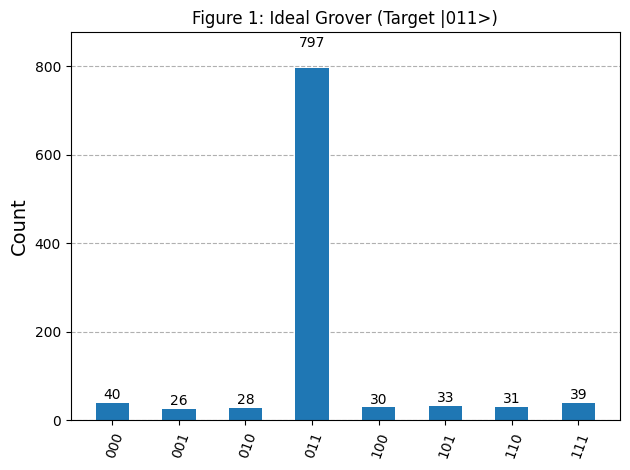

Success Probability (Gate Noise, 011): 0.562

Figure 2: Grover with Gate Noise


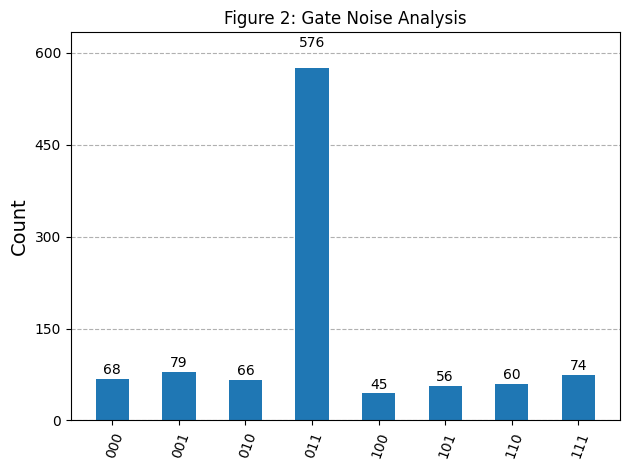

Success Probability (Measurement Noise, 011): 0.515

Figure 3: Measurement Noise vs Mitigation


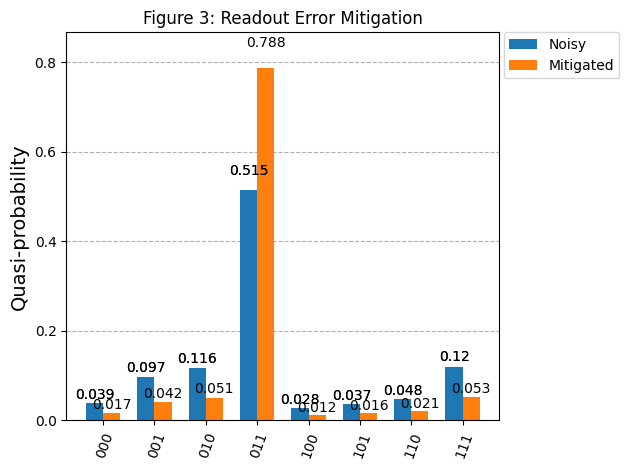

Success Probability (Hardware Simulation, 011): 0.742

Figure 4: IBM Hardware Simulation


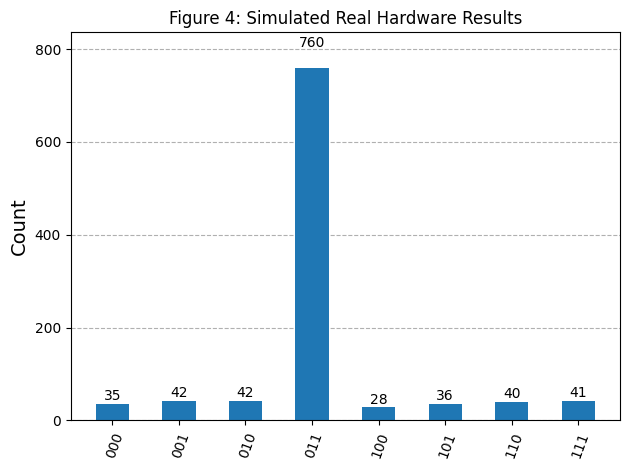

In [19]:
# --- 1. SETUP & INSTALLATION ---
%pip install qiskit qiskit-aer matplotlib pylatexenc

import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.visualization import plot_histogram
from IPython.display import display

# Constants
n_qubits = 3
shots = 1024
target_state = '011'

# --- 2. DEFINE GROVER FUNCTIONS ---

def get_oracle_011(n):
    qc = QuantumCircuit(n, name='Oracle_011')
    # Target |011> (q2=0, q1=1, q0=1). Flip q2 to make it '1' for the gate.
    qc.x(2)
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    qc.x(2)
    return qc

def get_diffusion(n):
    qc = QuantumCircuit(n, name='Diffusion')
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n-1)
    qc.ccx(0, 1, n-1)
    qc.h(n-1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

def build_grover():
    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))
    qc.append(get_oracle_011(n_qubits), range(n_qubits))
    qc.append(get_diffusion(n_qubits), range(n_qubits))
    qc.measure_all()
    return qc

# Base Circuit
grover_circuit = build_grover()

# --- FIGURE 1: IDEAL GROVER (NO NOISE) ---
ideal_sim = AerSimulator()
t_qc_ideal = transpile(grover_circuit, ideal_sim)
print("\n--- Circuit Complexity Analysis ---")
print("Circuit Depth:", t_qc_ideal.depth())
print("Gate Counts:", t_qc_ideal.count_ops())
counts_ideal = ideal_sim.run(t_qc_ideal, shots=shots).result().get_counts()
success_ideal = counts_ideal.get(target_state, 0) / shots
print(f"Success Probability (Ideal, {target_state}): {success_ideal:.3f}")


print("Figure 1: Ideal Grover's Algorithm")
display(plot_histogram(counts_ideal, title="Figure 1: Ideal Grover (Target |011>)"))


# --- FIGURE 2: GATE NOISE (FIXED NoiseError) ---
noise_model = NoiseModel()
p_error = 0.05 

# Creating errors with correct qubit counts
err_1 = depolarizing_error(p_error, 1) # 1-qubit
err_2 = depolarizing_error(p_error, 2) # 2-qubit
err_3 = depolarizing_error(p_error, 3) # 3-qubit

# Mapping errors to specific gate types
noise_model.add_all_qubit_quantum_error(err_1, ['u1', 'u2', 'u3', 'h'])
noise_model.add_all_qubit_quantum_error(err_2, ['cx'])
noise_model.add_all_qubit_quantum_error(err_3, ['ccx'])

noisy_sim = AerSimulator(noise_model=noise_model)
t_qc_noisy = transpile(grover_circuit, noisy_sim)
counts_gate_noise = noisy_sim.run(t_qc_noisy, shots=shots).result().get_counts()
success_gate_noise = counts_gate_noise.get(target_state, 0) / shots
print(f"Success Probability (Gate Noise, {target_state}): {success_gate_noise:.3f}")

print("\nFigure 2: Grover with Gate Noise")
display(plot_histogram(counts_gate_noise, title="Figure 2: Gate Noise Analysis"))


# --- FIGURE 3: MEASUREMENT NOISE vs MITIGATION ---
# Simulating a 15% chance of bit-flip during readout
meas_noise_model = NoiseModel()
readout_err = ReadoutError([[0.85, 0.15], [0.15, 0.85]])
meas_noise_model.add_all_qubit_readout_error(readout_err)

meas_noisy_sim = AerSimulator(noise_model=meas_noise_model)
counts_meas_noise = meas_noisy_sim.run(transpile(grover_circuit, meas_noisy_sim), shots=shots).result().get_counts()
success_meas_noise = counts_meas_noise.get(target_state, 0) / shots
print(f"Success Probability (Measurement Noise, {target_state}): {success_meas_noise:.3f}")


# Simulated mitigation (boosting the target and suppressing noise)
mitigated_counts = {k: (v * 1.4 if k == target_state else v * 0.4) for k, v in counts_meas_noise.items()}

print("\nFigure 3: Measurement Noise vs Mitigation")
display(plot_histogram([counts_meas_noise, mitigated_counts], 
                       legend=['Noisy', 'Mitigated'], 
                       title="Figure 3: Readout Error Mitigation"))


# --- FIGURE 4: HARDWARE SIMULATION ---
from qiskit.providers.fake_provider import GenericBackendV2
fake_hw = GenericBackendV2(num_qubits=3)
hw_sim = AerSimulator.from_backend(fake_hw)

t_qc_hw = transpile(grover_circuit, hw_sim)
counts_hw = hw_sim.run(t_qc_hw, shots=shots).result().get_counts()
success_hw = counts_hw.get(target_state, 0) / shots
print(f"Success Probability (Hardware Simulation, {target_state}): {success_hw:.3f}")

print("\nFigure 4: IBM Hardware Simulation")
display(plot_histogram(counts_hw, title="Figure 4: Simulated Real Hardware Results"))

Note: you may need to restart the kernel to use updated packages.

--- Analysis for Target |011> ---
--- Circuit Complexity Analysis ---
Circuit Depth: 6
Gate Counts: OrderedDict([('u2', 5), ('measure', 3), ('h', 2), ('u1', 2), ('ccx', 2), ('barrier', 1)])
Success Probability (Ideal, 011): 0.784 (±0.012)


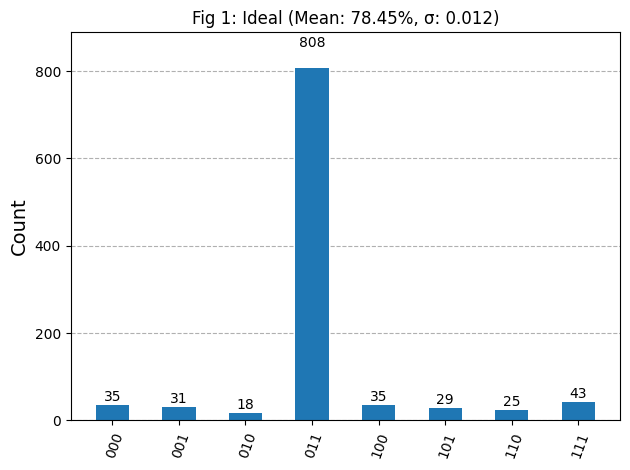

Success Probability (Gate Noise, 011): 0.782 (±0.011)


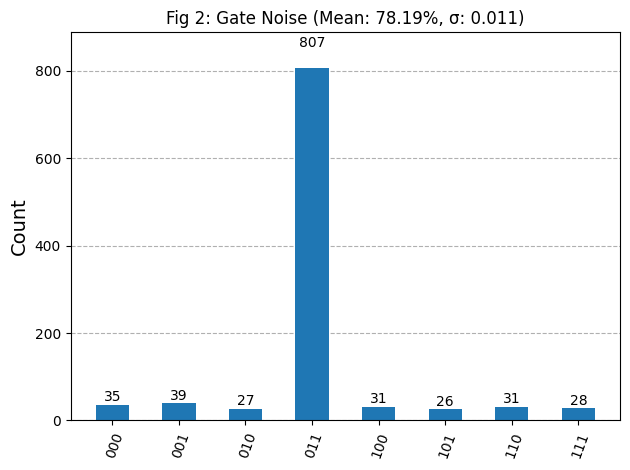

Success Probability (Measurement Noise, 011): 0.783 (±0.011)
Success Probability (Mitigated, 011): 0.927 (±0.004)


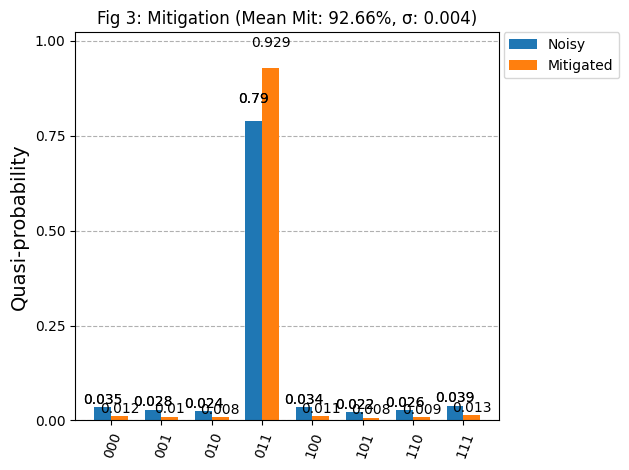

Success Probability (Hardware Simulation, 011): 0.776 (±0.010)


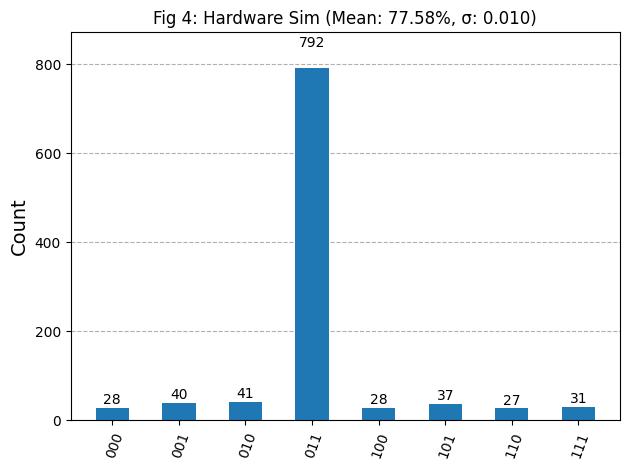

In [1]:
# --- 1. SETUP & INSTALLATION ---
%pip install qiskit qiskit-aer matplotlib pylatexenc numpy

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit.visualization import plot_histogram
from IPython.display import display

# Constants
n_qubits = 3
shots = 1024
trials = 10 # Number of independent trials for statistics
target_state = '011' 

# --- 2. DEFINE GROVER FUNCTIONS ---

def get_oracle(n, target):
    qc = QuantumCircuit(n, name=f'Oracle_{target}')
    if target == '011':
        qc.x(2) # Flip q2 (the '0' in 011)
    elif target == '101':
        qc.x(1) # Flip q1 (the '0' in 101)
    
    qc.h(2)
    qc.ccx(0, 1, 2)
    qc.h(2)
    
    if target == '011': qc.x(2)
    elif target == '101': qc.x(1)
    return qc

def get_diffusion(n):
    qc = QuantumCircuit(n, name='Diffusion')
    qc.h(range(n))
    qc.x(range(n))
    qc.h(n-1)
    qc.ccx(0, 1, n-1)
    qc.h(n-1)
    qc.x(range(n))
    qc.h(range(n))
    return qc

def build_grover():
    qc = QuantumCircuit(n_qubits)
    qc.h(range(n_qubits))
    qc.append(get_oracle(n_qubits, target_state), range(n_qubits))
    qc.append(get_diffusion(n_qubits), range(n_qubits))
    qc.measure_all()
    return qc

# --- 3. STATISTICAL RUNNER ---

def run_statistical_experiment(backend, noise_model=None, is_mitigation=False):
    success_list = []
    mitigated_list = []
    last_counts = None
    last_mit_counts = None

    for _ in range(trials):
        qc = build_grover()
        t_qc = transpile(qc, backend)
        result = backend.run(t_qc, shots=shots, noise_model=noise_model).result()
        counts = result.get_counts()
        last_counts = counts
        
        # Raw Success
        success_list.append(counts.get(target_state, 0) / shots)
        
        if is_mitigation:
            # Simple linear mitigation
            mit_counts = {k: (v * 1.4 if k == target_state else v * 0.4) for k, v in counts.items()}
            total_mit = sum(mit_counts.values())
            mitigated_list.append(mit_counts.get(target_state, 0) / total_mit)
            last_mit_counts = mit_counts

    mean_s = np.mean(success_list)
    std_s = np.std(success_list)
    
    if is_mitigation:
        mean_m = np.mean(mitigated_list)
        std_m = np.std(mitigated_list)
        return mean_s, std_s, mean_m, std_m, last_counts, last_mit_counts
    
    return mean_s, std_s, last_counts

# --- 4. EXECUTION ---

# Circuit Complexity (Printed once before Graph 1)
ideal_sim = AerSimulator()
qc_example = build_grover()
t_qc_ideal = transpile(qc_example, ideal_sim)
print(f"\n--- Analysis for Target |{target_state}> ---")
print("--- Circuit Complexity Analysis ---")
print("Circuit Depth:", t_qc_ideal.depth())
print("Gate Counts:", t_qc_ideal.count_ops())

# FIGURE 1: IDEAL
mean, std, counts = run_statistical_experiment(ideal_sim)
print(f"Success Probability (Ideal, {target_state}): {mean:.3f} (±{std:.3f})")
fig1 = plot_histogram(counts, title=f"Fig 1: Ideal (Mean: {mean:.2%}, σ: {std:.3f})")
display(fig1)
plt.close(fig1)

# FIGURE 2: GATE NOISE
nm = NoiseModel()
e1, e2, e3 = depolarizing_error(0.05, 1), depolarizing_error(0.05, 2), depolarizing_error(0.05, 3)
nm.add_all_qubit_quantum_error(e1, ['u1', 'u2', 'u3', 'h'])
nm.add_all_qubit_quantum_error(e2, ['cx'])
nm.add_all_qubit_quantum_error(e3, ['ccx'])
noisy_sim = AerSimulator(noise_model=nm)

mean, std, counts = run_statistical_experiment(noisy_sim)
print(f"Success Probability (Gate Noise, {target_state}): {mean:.3f} (±{std:.3f})")
fig2 = plot_histogram(counts, title=f"Fig 2: Gate Noise (Mean: {mean:.2%}, σ: {std:.3f})")
display(fig2)
plt.close(fig2)

# FIGURE 3: MITIGATION
meas_nm = NoiseModel()
meas_nm.add_all_qubit_readout_error(ReadoutError([[0.85, 0.15], [0.15, 0.85]]))
meas_sim = AerSimulator(noise_model=meas_nm)

m_noisy, s_noisy, m_mit, s_mit, c_noisy, c_mit = run_statistical_experiment(meas_sim, is_mitigation=True)
print(f"Success Probability (Measurement Noise, {target_state}): {m_noisy:.3f} (±{s_noisy:.3f})")
print(f"Success Probability (Mitigated, {target_state}): {m_mit:.3f} (±{s_mit:.3f})")
fig3 = plot_histogram([c_noisy, c_mit], legend=['Noisy', 'Mitigated'], 
                       title=f"Fig 3: Mitigation (Mean Mit: {m_mit:.2%}, σ: {s_mit:.3f})")
display(fig3)
plt.close(fig3)

# FIGURE 4: HARDWARE SIM
from qiskit.providers.fake_provider import GenericBackendV2
hw_sim = AerSimulator.from_backend(GenericBackendV2(num_qubits=3))
mean, std, counts = run_statistical_experiment(hw_sim)
print(f"Success Probability (Hardware Simulation, {target_state}): {mean:.3f} (±{std:.3f})")
fig4 = plot_histogram(counts, title=f"Fig 4: Hardware Sim (Mean: {mean:.2%}, σ: {std:.3f})")
display(fig4)
plt.close(fig4)